In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
##import squidpy as sq
import scvi
from scvi.model.utils import mde

sc.set_figure_params(figsize=(8, 8))

%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
%config InlineBackend.figure_format='retina'

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/dask/array/chunk_types.py:110: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy-cuda11x, cupy-cuda12x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  import cupy


In [2]:
wildtype=sc.read_h5ad('/exports/archive/hg-exon-skip/Qirong/data/wildtype_noCB.h5ad')
mdxbl6=sc.read_h5ad('/exports/archive/hg-exon-skip/Qirong/data/mdxbl6_noCB.h5ad')
mdx4cv=sc.read_h5ad('/exports/archive/hg-exon-skip/Qirong/data/mdx4cv_noCB.h5ad')
mdx52=sc.read_h5ad('/exports/archive/hg-exon-skip/Qirong/data/mdx52_noCB.h5ad')

In [4]:
wildtype.obs

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,pct_counts_mt,total_counts_hb,pct_counts_hb,label,batch,_scvi_batch,_scvi_labels,clusters,annotation,annotation_hlevel
AAACAAGTATCTCCCA-1,1,50,102,2765,7.925158,6728.0,8.814182,25.728300,32.862663,42.003567,...,11.667658,0.0,0.000000,wildtype,0,3,0,1,Central subpallium,Central subpallium
AAACACCAATAACTGC-1,1,59,19,4751,8.466321,16322.0,9.700331,19.354246,26.877834,36.533513,...,6.163460,0.0,0.000000,wildtype,0,3,0,2,Isocortex_2,Isocortex
AAACAGGGTCTATATT-1,1,47,13,2446,7.802618,6386.0,8.762020,34.231131,40.948951,49.639837,...,14.735359,0.0,0.000000,wildtype,0,3,0,7,Unknown,Unknown
AAACAGTGTTCCTGGG-1,1,73,43,3559,8.177516,9648.0,9.174609,16.987977,24.606136,34.836235,...,4.052653,0.0,0.000000,wildtype,0,3,0,5,Isocortex_1,Isocortex
AAACATTTCCCGGATT-1,1,61,97,2863,7.959975,6947.0,8.846210,22.354973,29.480351,39.311933,...,9.025478,0.0,0.000000,wildtype,0,3,0,1,Central subpallium,Central subpallium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTGTGTGTCAAGA-1,1,31,77,1944,7.573017,3653.0,8.203578,22.036682,29.318368,39.173282,...,7.144813,0.0,0.000000,wildtype,0,3,0,0,Unknown,Unknown
TTGTTTCACATCCAGG-1,1,58,42,2430,7.796058,6074.0,8.711937,33.157721,40.187685,49.110965,...,13.368456,0.0,0.000000,wildtype,0,3,0,6,Hippocampus Region_1,Hippocampus Formation
TTGTTTCATTAGTCTA-1,1,60,30,3060,8.026497,7259.0,8.890135,21.049731,29.136245,39.178950,...,5.455297,1.0,0.013776,wildtype,0,3,0,8,Fiber tract,Fiber tract
TTGTTTCCATACAACT-1,1,45,27,3836,8.252446,10703.0,9.278373,19.116136,27.029805,37.111090,...,5.587219,0.0,0.000000,wildtype,0,3,0,2,Isocortex_2,Isocortex


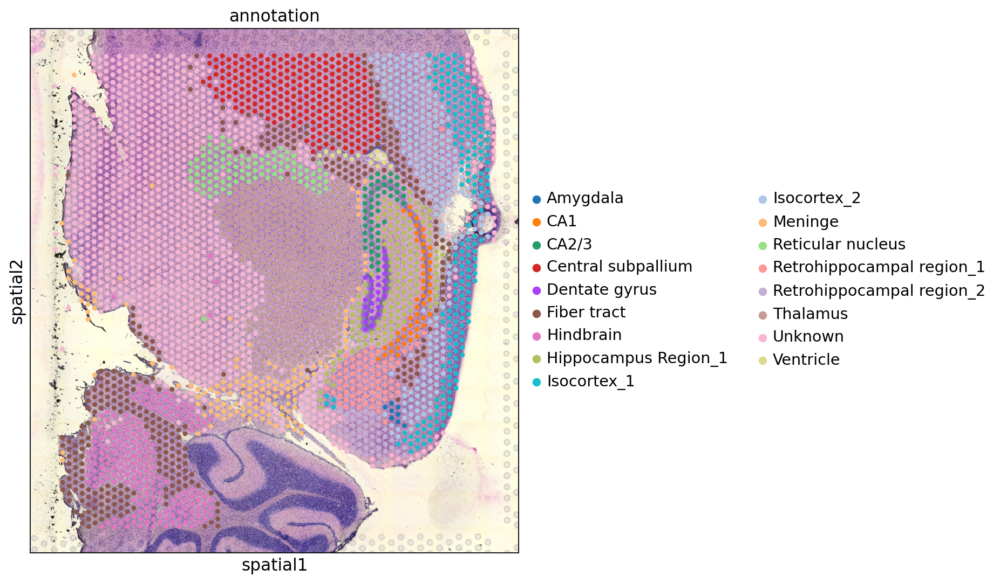

In [9]:
sc.pl.spatial(mdx52,color="annotation")

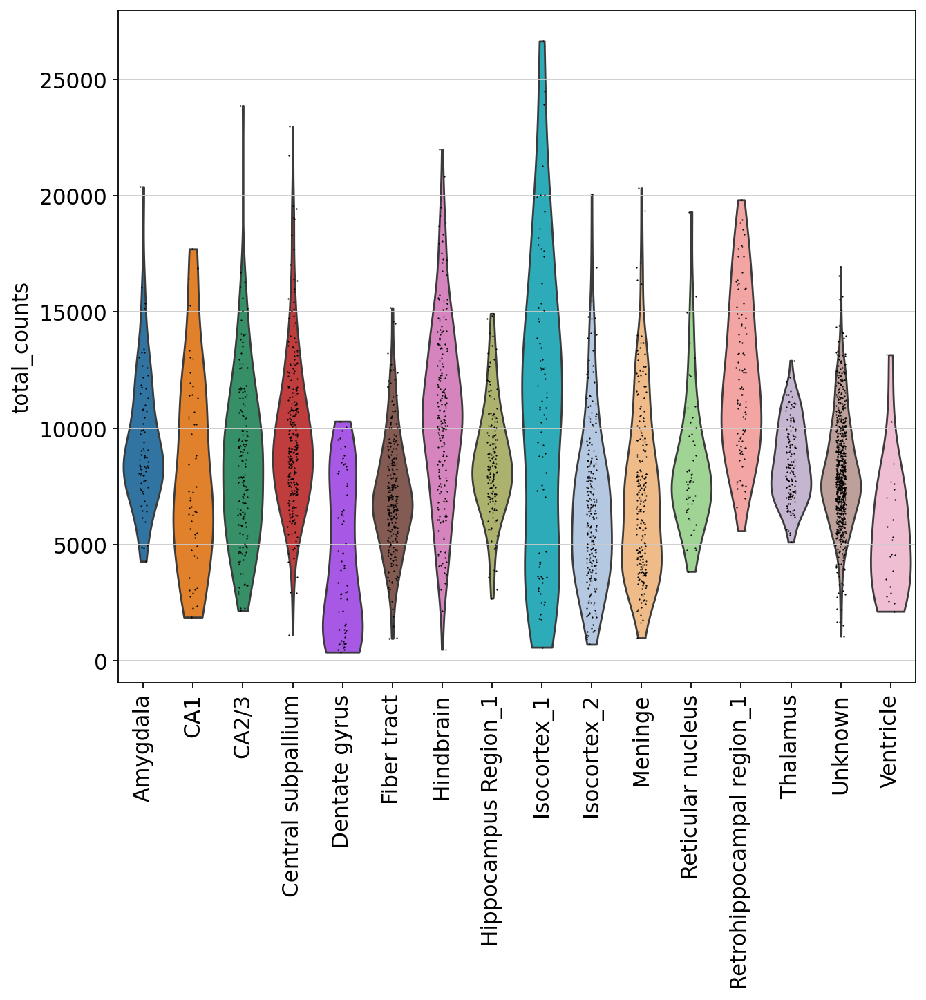

In [15]:
sc.pl.violin(mdx4cv,keys="total_counts",groupby="annotation",rotation=90)

In [3]:
CB_wildtype=pd.read_csv("/exports/archive/hg-exon-skip/Qirong/Visium_Brain/CB_barcode/CB_wildtype.csv")
CB_mdxbl6=pd.read_csv("/exports/archive/hg-exon-skip/Qirong/Visium_Brain/CB_barcode/CB_mdxbl6.csv")
CB_mdx4cv=pd.read_csv("/exports/archive/hg-exon-skip/Qirong/Visium_Brain/CB_barcode/CB_mdx4cv.csv")
CB_mdx52=pd.read_csv("/exports/archive/hg-exon-skip/Qirong/Visium_Brain/CB_barcode/CB_mdx52.csv")

In [16]:
wildtype_2=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2246715_wildtype/outs/")
mdxbl6_2=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2233108_mdxbl6/outs/")
mdx4cv_2=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2226038_mdx4cv/outs/")
mdx52_2=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2227912_mdx52/outs/")

wildtype_3=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2226778_wildtype_2/outs/")
mdxbl6_3=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2232232_mdxbl6/outs/")
mdx4cv_3=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2226039_mdx4cv/outs/")
wildtype_4=sc.read_visium("/exports/archive/hg-exon-skip/Qirong/Visium_brain_raw/Brain/Output/Batch2/AN2226778_wildtype/outs/")

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/exp

In [17]:
sc.pp.calculate_qc_metrics(wildtype, inplace=True)
sc.pp.calculate_qc_metrics(mdxbl6, inplace=True)
sc.pp.calculate_qc_metrics(mdx4cv, inplace=True)
sc.pp.calculate_qc_metrics(mdx52, inplace=True)

sc.pp.calculate_qc_metrics(wildtype_2, inplace=True)
sc.pp.calculate_qc_metrics(mdxbl6_2, inplace=True)
sc.pp.calculate_qc_metrics(mdx4cv_2, inplace=True)
sc.pp.calculate_qc_metrics(mdx52_2, inplace=True)
sc.pp.calculate_qc_metrics(wildtype_3, inplace=True)
sc.pp.calculate_qc_metrics(mdxbl6_3, inplace=True)
sc.pp.calculate_qc_metrics(mdx4cv_3, inplace=True)
sc.pp.calculate_qc_metrics(wildtype_4, inplace=True)

In [26]:
wildtype = wildtype[~wildtype.obs_names.isin(CB_wildtype["Barcode"])]
mdxbl6 = mdxbl6[~mdxbl6.obs_names.isin(CB_mdxbl6["Barcode"])]
mdx4cv = mdx4cv[~mdx4cv.obs_names.isin(CB_mdx4cv["Barcode"])]
mdx52 = mdx52[~mdx52.obs_names.isin(CB_mdx52["Barcode"])]

In [18]:
wildtype.obs["Slide"]=1
mdxbl6.obs["Slide"]=1
mdx4cv.obs["Slide"]=1
mdx52.obs["Slide"]=1

wildtype_2.obs["Slide"]=2
mdxbl6_2.obs["Slide"]=2
mdx4cv_2.obs["Slide"]=2
mdx52_2.obs["Slide"]=2

wildtype_3.obs["Slide"]=3
mdxbl6_3.obs["Slide"]=3
mdx4cv_3.obs["Slide"]=3
wildtype_4.obs["Slide"]=3


In [19]:
wildtype.obs["Batch"]=1
mdxbl6.obs["Batch"]=1
mdx4cv.obs["Batch"]=1
mdx52.obs["Batch"]=1

wildtype_2.obs["Batch"]=2
mdxbl6_2.obs["Batch"]=2
mdx4cv_2.obs["Batch"]=2
mdx52_2.obs["Batch"]=2

wildtype_3.obs["Batch"]=2
mdxbl6_3.obs["Batch"]=2
mdx4cv_3.obs["Batch"]=2
wildtype_4.obs["Batch"]=2

In [20]:
wildtype.obs["Sample"]="wildtype"
mdxbl6.obs["Sample"]="mdxbl6"
mdx4cv.obs["Sample"]="mdx4cv"
mdx52.obs["Sample"]="mdx52"

wildtype_2.obs["Sample"]="wildtype_2"
mdxbl6_2.obs["Sample"]="mdxbl6_2"
mdx4cv_2.obs["Sample"]="mdx4cv_2"
mdx52_2.obs["Sample"]="mdx52_2"

wildtype_3.obs["Sample"]="wildtype_3"
mdxbl6_3.obs["Sample"]="mdxbl6_3"
mdx4cv_3.obs["Sample"]="mdx4cv_3"
wildtype_4.obs["Sample"]="wildtype_4"

In [21]:
wildtype.var_names_make_unique()
mdxbl6.var_names_make_unique()
mdx4cv.var_names_make_unique()
mdx52.var_names_make_unique()

wildtype_2.var_names_make_unique()
mdxbl6_2.var_names_make_unique()
mdx4cv_2.var_names_make_unique()
mdx52_2.var_names_make_unique()

wildtype_3.var_names_make_unique()
mdxbl6_3.var_names_make_unique()
mdx4cv_3.var_names_make_unique()
wildtype_4.var_names_make_unique()


In [22]:
adata = wildtype.concatenate(mdxbl6,mdx4cv,mdx52,wildtype_2,mdxbl6_2,mdx4cv_2,mdx52_2,wildtype_3,mdxbl6_3,mdx4cv_3,wildtype_4)

/tmp/ipykernel_1176411/2641265134.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = wildtype.concatenate(mdxbl6,mdx4cv,mdx52,wildtype_2,mdxbl6_2,mdx4cv_2,mdx52_2,wildtype_3,mdxbl6_3,mdx4cv_3,wildtype_4)


In [23]:
adata.obs["Slide"] = adata.obs["Slide"].astype("category")

In [24]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [25]:
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat_v3",
    n_top_genes=2000,
    layer="counts",
    batch_key="Slide",
    subset=True
)

In [26]:
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata)

/tmp/ipykernel_1176411/1237206339.py:4: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


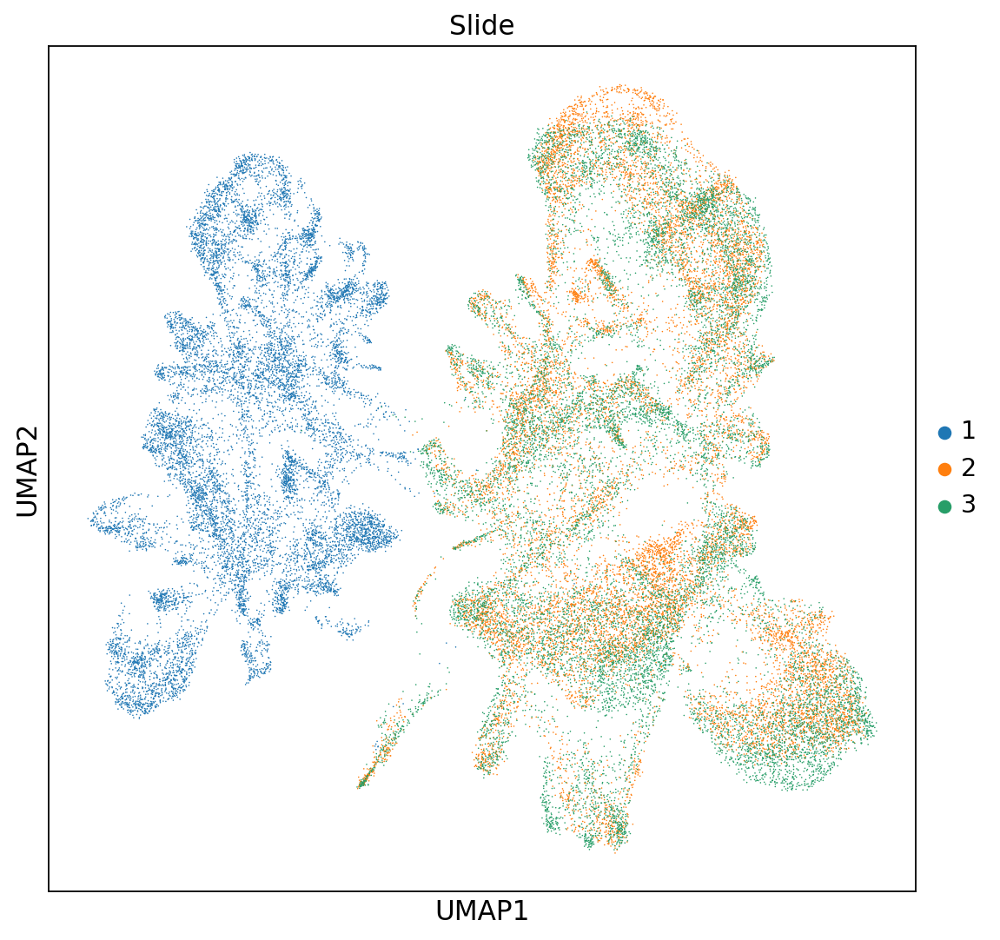

In [27]:
sc.pl.umap(
    adata,
    color="Slide",
    # Setting a smaller point size to get prevent overlap
    size=2,
)

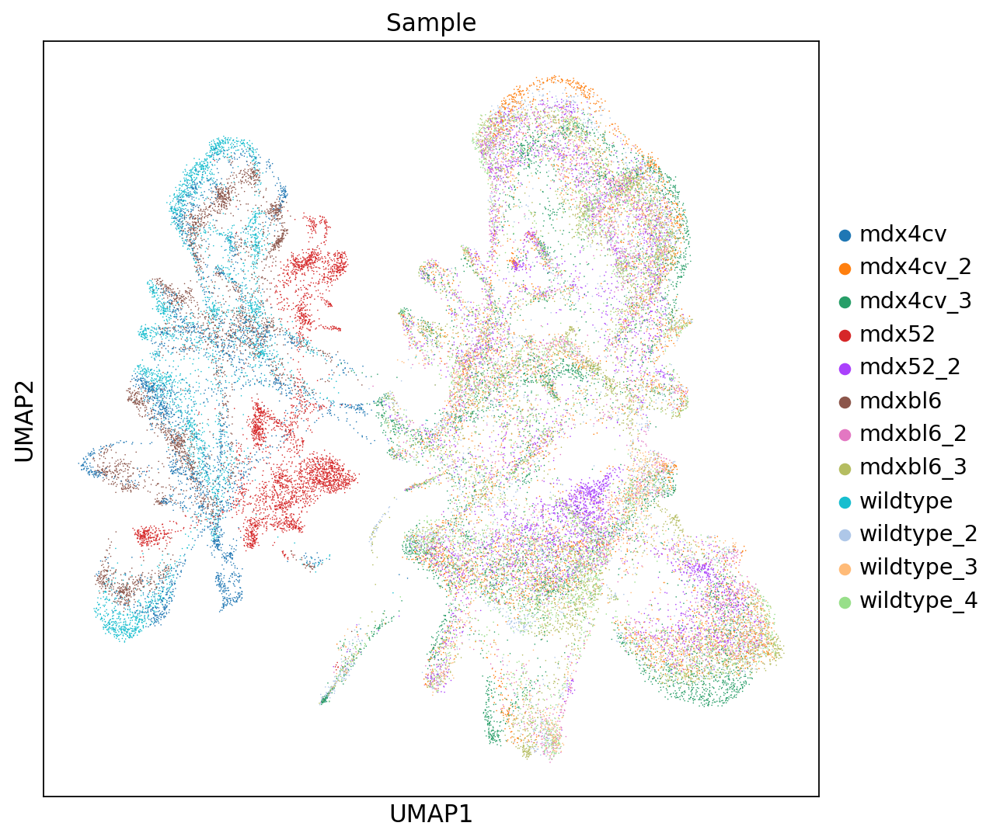

In [28]:
sc.pl.umap(
    adata,
    color="Sample",
    # Setting a smaller point size to get prevent overlap
    size=2,
)

In [29]:
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="Batch")

In [30]:
model = scvi.model.SCVI(adata, n_layers=2, n_latent=30, gene_likelihood="nb")

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/scvi/model/_scvi.py:161: UserWarning: This dataset has some empty cells, this might fail inference.Data should be filtered with `scanpy.pp.filter_cells()`
  library_log_means, library_log_vars = _init_library_size(


In [31]:
model.train()

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 191/191: 100%|██████████| 191/191 [07:13<00:00,  2.21s/it, v_num=1, train_loss_step=968, train_loss_epoch=955]    

`Trainer.fit` stopped: `max_epochs=191` reached.


Epoch 191/191: 100%|██████████| 191/191 [07:13<00:00,  2.27s/it, v_num=1, train_loss_step=968, train_loss_epoch=955]


In [32]:
SCVI_LATENT_KEY = "X_scVI"
adata.obsm[SCVI_LATENT_KEY] = model.get_latent_representation()

In [33]:
SCVI_MDE_KEY = "X_scVI_MDE"
adata.obsm[SCVI_MDE_KEY] = scvi.model.utils.mde(adata.obsm[SCVI_LATENT_KEY])

INFO     Using cuda:0 for `pymde.preserve_neighbors`.                                                              


/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...


Dec 23 11:15:37 AM: Your dataset appears to contain duplicated items (rows); when embedding, you should typically have unique items.
Dec 23 11:15:37 AM: The following items have duplicates [13660 14392 18022 38098]


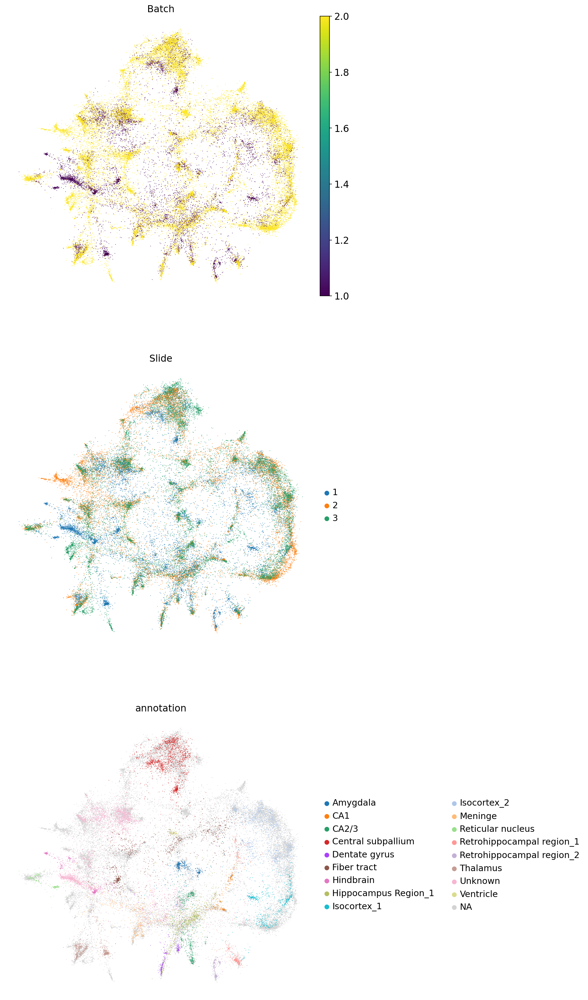

In [34]:
sc.pl.embedding(
    adata,
    basis="X_scVI_MDE",
    color=["Batch","Slide","annotation"],
    frameon=False,
    ncols=1,
)

In [35]:
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.3)
sc.tl.leiden(adata, key_added="leiden_scVI")

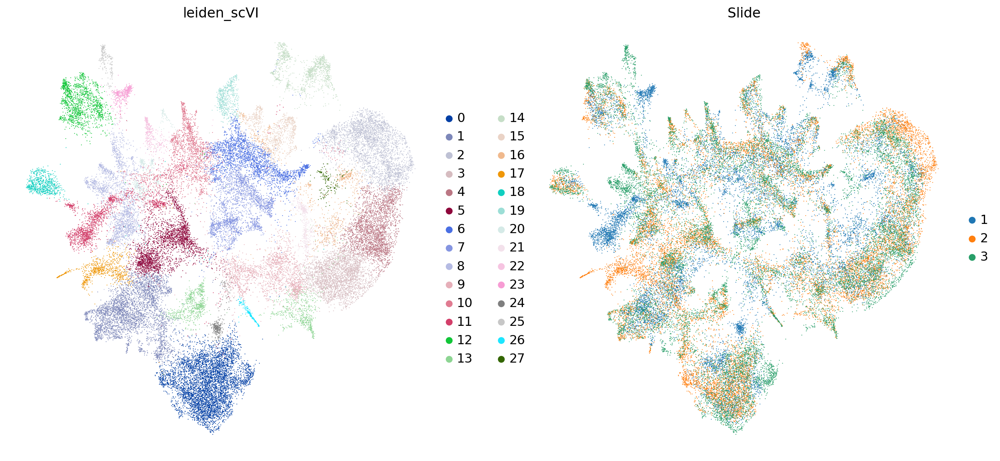

In [37]:
sc.pl.umap(
    adata,
    color=["leiden_scVI","Slide"],
    frameon=False,
)

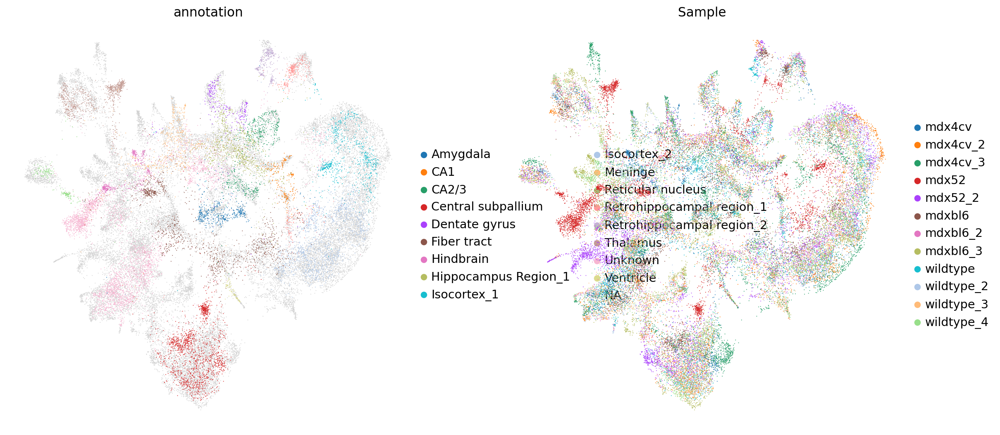

In [38]:
sc.pl.umap(
    adata,
    color=["annotation","Sample"],
    frameon=False,
)

In [61]:
wildtype_obs=adata.obs[adata.obs["Sample"]=="wildtype"]

In [64]:
slection

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,_scvi_labels,clusters,annotation,annotation_hlevel,Slide,Batch,Sample,leiden,leiden_scVI,C_scANVI
AAACAAGTATCTCCCA-1,1,50,102,2462,7.809135,6286.0,8.746240,33.678015,42.236717,51.686287,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,17,6,Meninge
AAACAATCTACTAGCA-1,1,3,43,3744,8.228177,10387.0,9.248406,27.784731,34.485414,43.246366,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,2,2,Isocortex_1
AAACACCAATAACTGC-1,1,59,19,5230,8.562358,19945.0,9.900784,22.461770,30.107796,39.989972,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,12,13,Isocortex_2
AAACAGAGCGACTCCT-1,1,14,94,4457,8.402456,14764.0,9.600015,21.288269,28.826876,38.546464,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,20,14,Retrohippocampal region_1
AAACAGCTTTCAGAAG-1,1,43,9,6665,8.804775,34035.0,10.435174,20.440723,27.671515,37.041281,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,4,3,Isocortex_2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTTCACATCCAGG-1,1,58,42,2066,7.633854,4984.0,8.514189,31.621188,39.807384,49.919743,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,0,0,Central subpallium
TTGTTTCATTAGTCTA-1,1,60,30,3387,8.127995,10192.0,9.229457,27.609890,35.351256,45.094192,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,0,0,Central subpallium
TTGTTTCCATACAACT-1,1,45,27,2563,7.849324,6319.0,8.751474,26.633961,34.309226,44.294983,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,0,0,Central subpallium
TTGTTTGTATTACACG-1,1,73,41,5647,8.639057,19878.0,9.897419,17.023845,23.930979,33.177382,...,17,NaN,Unpredicted,NaN,2,2,wildtype_2,26,1,Central subpallium


In [40]:
import pandas as pd

slection= adata.obs[adata.obs["Sample"]=="mdxbl6_3"]

slection.index = slection.index.str.replace(r"-\d+$", "", regex=True)
annotations = pd.Series(slection['leiden_scVI'].values, index=slection.index)
mdxbl6_3.obs['leiden_scVI'] = annotations.reindex(slection.index).values

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1130: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(


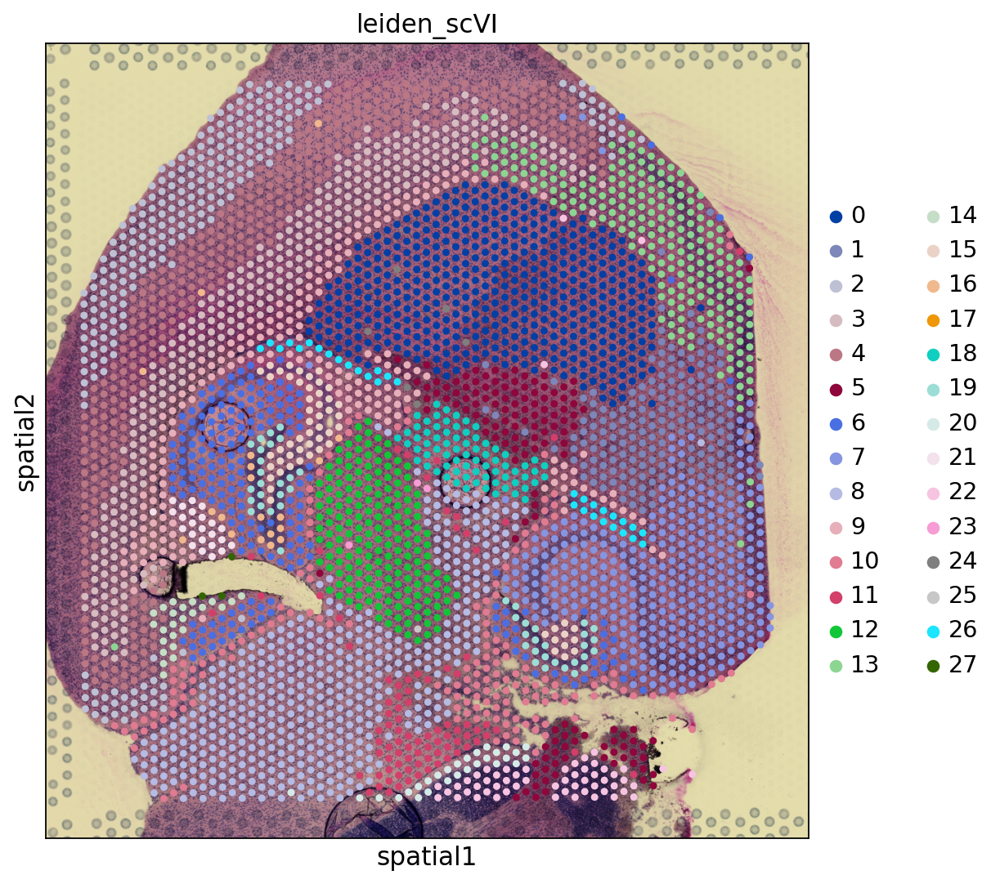

In [41]:
sc.pl.spatial(mdxbl6_3,color=["leiden_scVI"],label=True)

In [43]:
adata.obs['annotation'] = adata.obs['annotation'].cat.add_categories('Unpredicted')
adata.obs['annotation'].fillna('Unpredicted', inplace=True)

/tmp/ipykernel_1176411/3670938485.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata.obs['annotation'].fillna('Unpredicted', inplace=True)


In [45]:
scanvi_model = scvi.model.SCANVI.from_scvi_model(
    model,
    adata=adata,
    unlabeled_category="Unpredicted",
    labels_key='annotation',
)

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/scvi/model/_scanvi.py:139: UserWarning: This dataset has some empty cells, this might fail inference.Data should be filtered with `scanpy.pp.filter_cells()`
  library_log_means, library_log_vars = _init_library_size(self.adata_manager, n_batch)


In [47]:
scanvi_model.train()

INFO     Training for 10 epochs.                                                                                   


/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 10/10: 100%|██████████| 10/10 [01:02<00:00,  6.21s/it, v_num=1, train_loss_step=890, train_loss_epoch=884]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [01:02<00:00,  6.22s/it, v_num=1, train_loss_step=890, train_loss_epoch=884]


In [48]:
SCANVI_LATENT_KEY = "X_scANVI"
SCANVI_PREDICTION_KEY = "C_scANVI"

adata.obsm[SCANVI_LATENT_KEY] = scanvi_model.get_latent_representation(adata)
adata.obs[SCANVI_PREDICTION_KEY] = scanvi_model.predict(adata)

In [49]:
from scvi.model.utils import mde
SCANVI_MDE_KEY = "X_mde_scanvi"
adata.obsm[SCANVI_MDE_KEY] = mde(adata.obsm[SCANVI_LATENT_KEY])

INFO     Using cuda:0 for `pymde.preserve_neighbors`.                                                              


/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /exports/archive/hg-exon-skip/Qirong/conda/envs/scvi ...


Dec 23 11:22:07 AM: Your dataset appears to contain duplicated items (rows); when embedding, you should typically have unique items.
Dec 23 11:22:07 AM: The following items have duplicates [13236 13660 14391 16258 16598 18022 36854 38098]


In [50]:
adata.obs["annotation"]=adata.obs["annotation"].astype('category')

In [51]:
adata.obs.C_scANVI = pd.Categorical(
    adata.obs.C_scANVI.values, categories=adata.obs["annotation"].cat.categories
)

In [52]:
sc.set_figure_params(figsize=(12, 12))

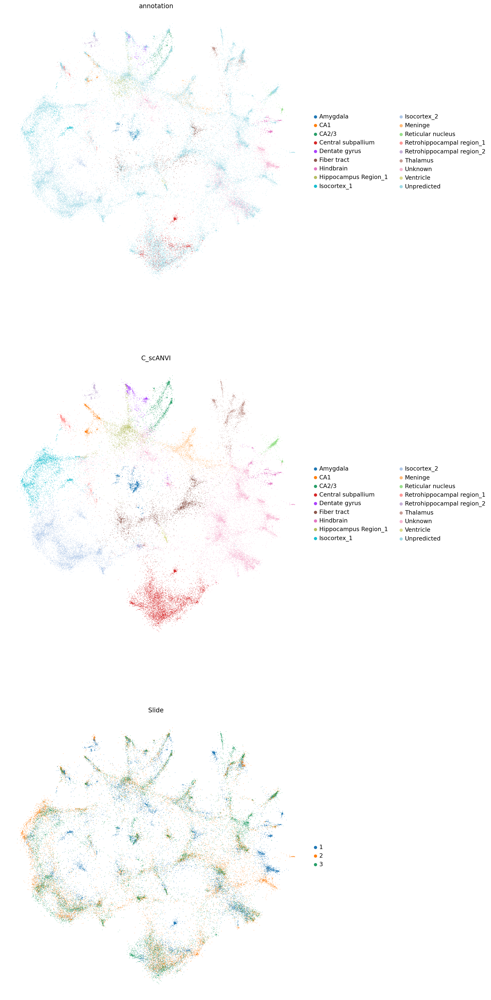

In [53]:
sc.pl.embedding(
    adata,
    basis=SCANVI_MDE_KEY,
    color=["annotation", SCANVI_PREDICTION_KEY,"Slide"],
    ncols=1,
    frameon=False
)

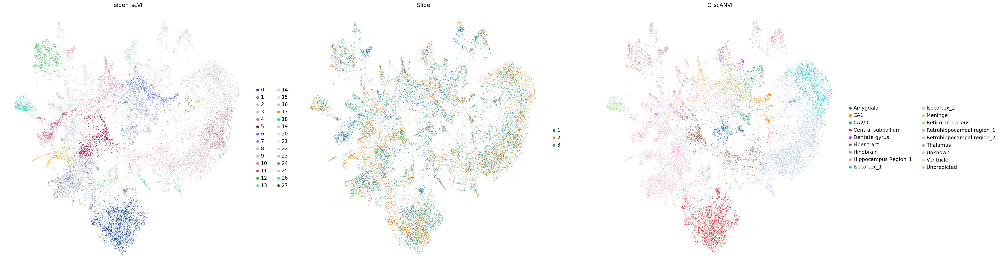

In [54]:
sc.pl.umap(
    adata,
    color=["leiden_scVI","Slide",SCANVI_PREDICTION_KEY],
    frameon=False,
)

In [86]:
import pandas as pd

slection= adata.obs[adata.obs["Sample"]=="mdx4cv_2"]

slection.index = slection.index.str.replace(r"-\d+$", "", regex=True)
annotations = pd.Series(slection['C_scANVI'].values, index=slection.index)
mdx4cv_2.obs['C_scANVI'] = annotations.reindex(slection.index).values

/exports/archive/hg-exon-skip/Qirong/conda/envs/scvi-env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1130: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(


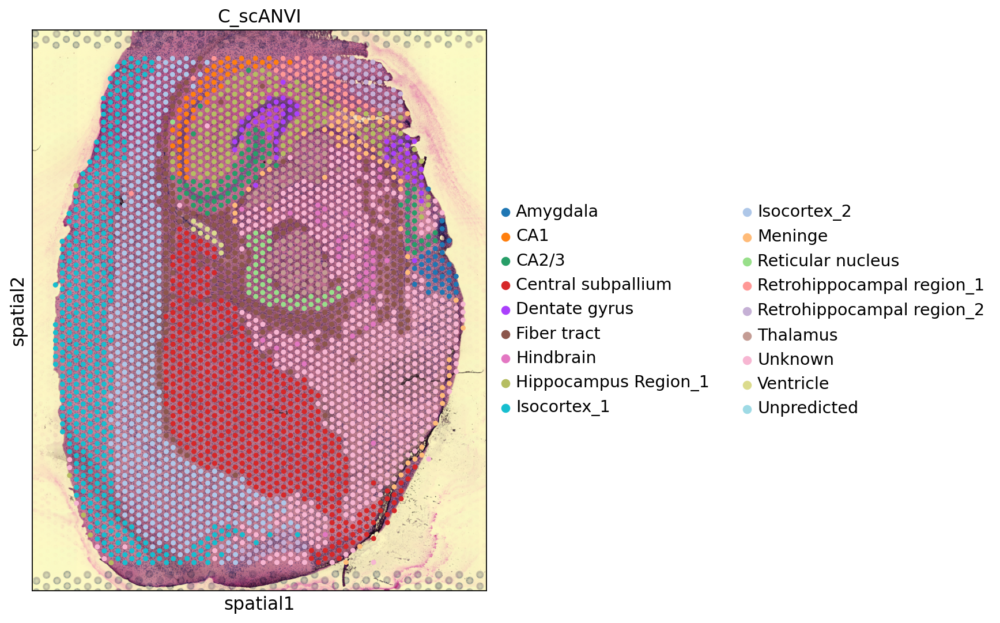

In [87]:
sc.set_figure_params(figsize=(8, 8))
sc.pl.spatial(mdx4cv_2,color=["C_scANVI"],label=True)

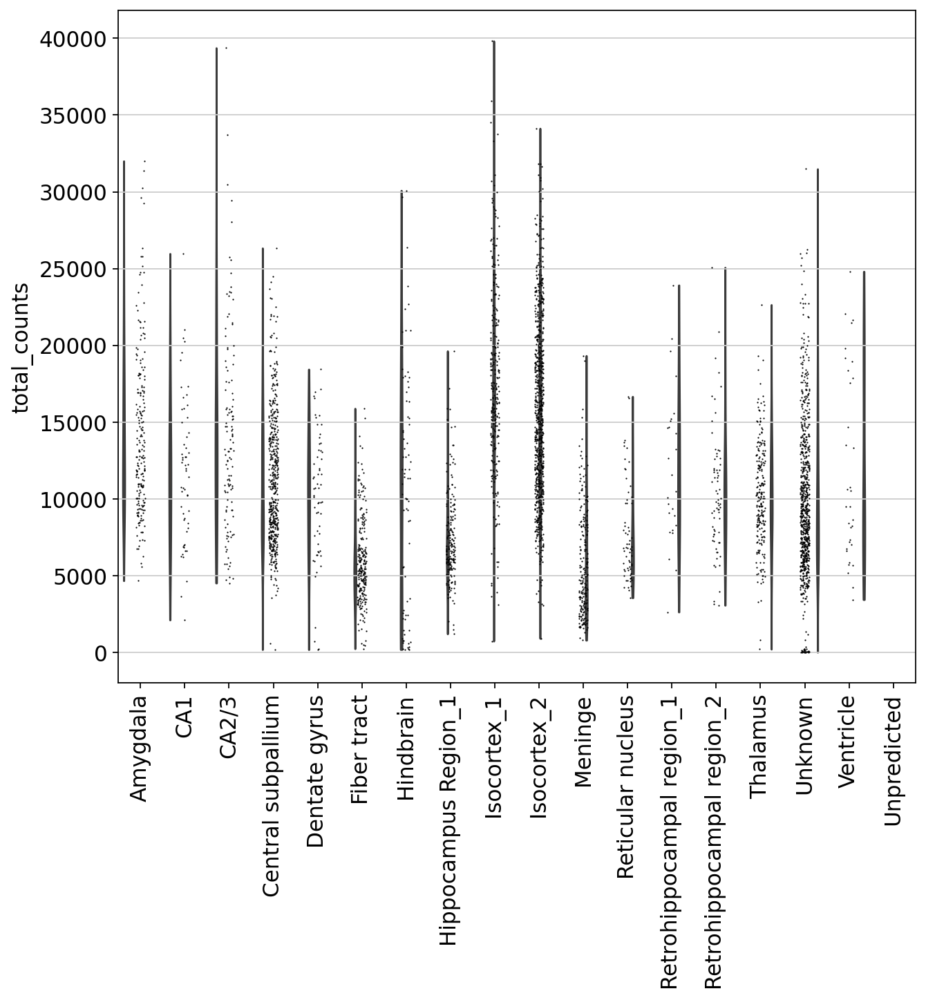

In [59]:
sc.pl.violin(mdxbl6_3,keys="total_counts",groupby="C_scANVI",rotation=90)

In [96]:
adata.obs.index.str.replace(r'-\d+$', '', regex=True)

Index(['AAACAAGTATCTCCCA-1', 'AAACACCAATAACTGC-1', 'AAACAGGGTCTATATT-1',
       'AAACAGTGTTCCTGGG-1', 'AAACATTTCCCGGATT-1', 'AAACCCGAACGAAATC-1',
       'AAACCGGAAATGTTAA-1', 'AAACCGGGTAGGTACC-1', 'AAACCGTTCGTCCAGG-1',
       'AAACCTAAGCAGCCGG-1',
       ...
       'TTGTGGTATAGGTATG-1', 'TTGTGGTGGTACTAAG-1', 'TTGTGTATGCCACCAA-1',
       'TTGTGTTTCCCGAAAG-1', 'TTGTTAGCAAATTCGA-1', 'TTGTTCAGTGTGCTAC-1',
       'TTGTTGTGTGTCAAGA-1', 'TTGTTTCACATCCAGG-1', 'TTGTTTCATTAGTCTA-1',
       'TTGTTTCCATACAACT-1'],
      dtype='object', length=41025)

In [97]:
adata.obs.index = adata.obs.index.str.replace(r'-1-\d+', '', regex=True)

In [98]:
adata.obs.index = adata.obs.index + '-1'

In [99]:
adata.obs

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,_scvi_batch,_scvi_labels,clusters,annotation,annotation_hlevel,Slide,Sample,leiden,leiden_scVI,C_scANVI
AAACAAGTATCTCCCA-1,1,50,102,2765.0,7.925158,6728.0,8.814182,25.728300,32.862663,42.003567,...,0,3,1,Central subpallium,Central subpallium,1,wildtype,13,1,Central subpallium
AAACACCAATAACTGC-1,1,59,19,4751.0,8.466321,16322.0,9.700331,19.354246,26.877834,36.533513,...,0,9,2,Isocortex_2,Isocortex,1,wildtype,7,0,Isocortex_2
AAACAGGGTCTATATT-1,1,47,13,2446.0,7.802618,6386.0,8.762020,34.231131,40.948951,49.639837,...,0,15,7,Unknown,Unknown,1,wildtype,4,3,Hippocampus Region_1
AAACAGTGTTCCTGGG-1,1,73,43,3559.0,8.177516,9648.0,9.174609,16.987977,24.606136,34.836235,...,0,8,5,Isocortex_1,Isocortex,1,wildtype,7,4,Isocortex_1
AAACATTTCCCGGATT-1,1,61,97,2863.0,7.959975,6947.0,8.846210,22.354973,29.480351,39.311933,...,0,3,1,Central subpallium,Central subpallium,1,wildtype,13,1,Central subpallium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,1,24,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,17,NaN,Unpredicted,NaN,3,wildtype_4,5,3,Hippocampus Region_1
TTGTTGTGTGTCAAGA-1,1,31,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,17,NaN,Unpredicted,NaN,3,wildtype_4,5,3,Meninge
TTGTTTCACATCCAGG-1,1,58,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,17,NaN,Unpredicted,NaN,3,wildtype_4,0,1,Central subpallium
TTGTTTCATTAGTCTA-1,1,60,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,17,NaN,Unpredicted,NaN,3,wildtype_4,0,1,Central subpallium


In [88]:
unique_samples = adata.obs["Sample"].unique()

# Step 2: Export each sample's data to a separate Excel file
for sample in unique_samples:
    # Filter the DataFrame for the current sample
    sample_data = adata.obs[adata.obs["Sample"] == sample]
    
    # Define the filename
    filename = f"/exports/humgen/qmao/{sample}.csv"
    
    # Export to Excel
    sample_data.to_csv(filename, index=True)

    print(f"Exported {sample} data to {filename}")

Exported wildtype data to /exports/humgen/qmao/wildtype.csv
Exported mdxbl6 data to /exports/humgen/qmao/mdxbl6.csv
Exported mdx4cv data to /exports/humgen/qmao/mdx4cv.csv
Exported mdx52 data to /exports/humgen/qmao/mdx52.csv
Exported wildtype_2 data to /exports/humgen/qmao/wildtype_2.csv
Exported mdxbl6_2 data to /exports/humgen/qmao/mdxbl6_2.csv
Exported mdx4cv_2 data to /exports/humgen/qmao/mdx4cv_2.csv
Exported mdx52_2 data to /exports/humgen/qmao/mdx52_2.csv
Exported wildtype_3 data to /exports/humgen/qmao/wildtype_3.csv
Exported mdxbl6_3 data to /exports/humgen/qmao/mdxbl6_3.csv
Exported mdx4cv_3 data to /exports/humgen/qmao/mdx4cv_3.csv
Exported wildtype_4 data to /exports/humgen/qmao/wildtype_4.csv


In [89]:
model.save("/exports/archive/hg-exon-skip/Qirong/Visium_scvi/")

In [90]:
adata.obs['in_tissue'] = adata.obs['in_tissue'].astype(str)

In [91]:
adata.obs

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,_scvi_labels,clusters,annotation,annotation_hlevel,Slide,Batch,Sample,leiden,leiden_scVI,C_scANVI
AAACAAGTATCTCCCA-1-0,1,50,102,2662,7.887209,5459.0,8.605204,18.446602,25.572449,35.043048,...,3,1,Central subpallium,Central subpallium,1,1,wildtype,14,0,Central subpallium
AAACACCAATAACTGC-1-0,1,59,19,4633,8.441176,14171.0,9.559024,16.209160,23.660998,33.462706,...,9,2,Isocortex_2,Isocortex,1,1,wildtype,7,4,Isocortex_2
AAACAGGGTCTATATT-1-0,1,47,13,2341,7.758761,4961.0,8.509564,25.519049,32.453134,41.644830,...,15,7,Unknown,Unknown,1,1,wildtype,5,6,Unknown
AAACAGTGTTCCTGGG-1-0,1,73,43,3448,8.145840,8620.0,9.061956,15.580046,23.236659,33.271462,...,8,5,Isocortex_1,Isocortex,1,1,wildtype,7,2,Isocortex_1
AAACATTTCCCGGATT-1-0,1,61,97,2760,7.923348,5815.0,8.668368,16.646604,24.178848,34.135856,...,3,1,Central subpallium,Central subpallium,1,1,wildtype,14,0,Central subpallium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1-11,1,24,64,1490,7.307202,3452.0,8.146998,37.833140,46.668598,56.460023,...,17,NaN,Unpredicted,NaN,3,2,wildtype_4,8,6,Hippocampus Region_1
TTGTTGTGTGTCAAGA-1-11,1,31,77,1491,7.307873,3229.0,8.080237,32.734593,42.520904,53.762775,...,17,NaN,Unpredicted,NaN,3,2,wildtype_4,8,6,Hippocampus Region_1
TTGTTTCACATCCAGG-1-11,1,58,42,2915,7.977968,7590.0,8.934719,24.690382,32.529644,42.200264,...,17,NaN,Unpredicted,NaN,3,2,wildtype_4,0,0,Central subpallium
TTGTTTCATTAGTCTA-1-11,1,60,30,2437,7.798933,5937.0,8.689128,28.162372,37.342092,47.684015,...,17,NaN,Unpredicted,NaN,3,2,wildtype_4,0,0,Central subpallium


In [92]:
column1 = 'leiden_scVI'
column2 = 'C_scANVI'

# Create a frequency table
frequency_table = (
    adata.obs.groupby(column1)[column2]
    .value_counts()
    .unstack(fill_value=0)
)

# Display the table
print(frequency_table)

C_scANVI     Amygdala  CA1  CA2/3  Central subpallium  Dentate gyrus  \
leiden_scVI                                                            
0                   0    0      0                5071              0   
1                  15    0      0                 332              2   
2                   2    0      0                   0              0   
3                   2    0      0                   0              0   
4                   9    1      0                   0              0   
5                   0    0      0                  11              0   
6                   3  377     84                   1             36   
7                 970    0    573                   0             34   
8                   0    0      1                   0              0   
9                   3    0     15                  31              6   
10                  3    0      3                   2              2   
11                  0    0      0                   5           

/tmp/ipykernel_1176411/3021931405.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(column1)[column2]


In [116]:
# Group by 'leiden_scVI' and find the most frequent 'C_scANVI' label
most_frequent_labels = (
    adata.obs.groupby('leiden_scVI')['C_scANVI']
    .agg(lambda x: x.value_counts().idxmax())
)

# Assign these labels back to the AnnData object
adata.obs['leiden_scVI_assigned_label'] = adata.obs['leiden_scVI'].map(most_frequent_labels)


/tmp/ipykernel_2390140/1285474786.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby('leiden_scVI')['C_scANVI']


In [117]:
adata.obs

,in_tissue,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,...,_scvi_labels,clusters,annotation,annotation_hlevel,Slide,Sample,leiden,leiden_scVI,C_scANVI,leiden_scVI_assigned_label
AAACAAGTATCTCCCA-1,1,2765.0,7.925158,6728.0,8.814182,25.728300,32.862663,42.003567,58.100476,785.0,...,3,1,Central subpallium,Central subpallium,1,wildtype,13,1,Central subpallium,Central subpallium
AAACACCAATAACTGC-1,1,4751.0,8.466321,16322.0,9.700331,19.354246,26.877834,36.533513,52.671241,1006.0,...,9,2,Isocortex_2,Isocortex,1,wildtype,7,0,Isocortex_2,Isocortex_2
AAACAGGGTCTATATT-1,1,2446.0,7.802618,6386.0,8.762020,34.231131,40.948951,49.639837,64.390855,941.0,...,15,7,Unknown,Unknown,1,wildtype,4,3,Hippocampus Region_1,Hippocampus Region_1
AAACAGTGTTCCTGGG-1,1,3559.0,8.177516,9648.0,9.174609,16.987977,24.606136,34.836235,51.855307,391.0,...,8,5,Isocortex_1,Isocortex,1,wildtype,7,4,Isocortex_1,Isocortex_1
AAACATTTCCCGGATT-1,1,2863.0,7.959975,6947.0,8.846210,22.354973,29.480351,39.311933,56.024183,627.0,...,3,1,Central subpallium,Central subpallium,1,wildtype,13,1,Central subpallium,Central subpallium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17,NaN,Unpredicted,NaN,3,wildtype_4,5,3,Hippocampus Region_1,Hippocampus Region_1
TTGTTGTGTGTCAAGA-1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17,NaN,Unpredicted,NaN,3,wildtype_4,5,3,Meninge,Hippocampus Region_1
TTGTTTCACATCCAGG-1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17,NaN,Unpredicted,NaN,3,wildtype_4,0,1,Central subpallium,Central subpallium
TTGTTTCATTAGTCTA-1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17,NaN,Unpredicted,NaN,3,wildtype_4,0,1,Central subpallium,Central subpallium


In [93]:
del adata.obs['array_row']
del adata.obs['array_col']

In [94]:
adata.write_h5ad("/exports/archive/hg-exon-skip/Qirong/Visium_merged.h5ad")

In [115]:
frequency_table.to_csv('/exports/archive/hg-exon-skip/Qirong/Visium_Brain/frequency_table.csv')